In [1]:
# ==============================================================================
# STEP 1: INSTALL & SETUP
# ==============================================================================
import os
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Install Dependencies (Quietly)
print("⏳ Installing libraries... (This takes ~2 mins)")
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps xformers "trl<0.9.0" peft accelerate bitsandbytes
!pip install -q evaluate jiwer sacrebleu seaborn matplotlib

Mounted at /content/drive
⏳ Installing libraries... (This takes ~2 mins)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.3/289.3 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 159.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.9/224.9 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.2/245.2 kB 24.1 MB/s e

In [2]:
# 3. Imports
import torch
from unsloth import FastLanguageModel
from datasets import load_dataset
from trl import SFTTrainer
from transformers import TrainingArguments, TextStreamer
import numpy as np
import pandas as pd
import evaluate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import re

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [4]:
# ==============================================================================
# STEP 2: CONFIGURATION & MODEL LOADING
# ==============================================================================

# PATHS (Update these if needed)
word_model_path = "/content/drive/MyDrive/Marma_Translator_Model"  # YOUR PREVIOUS WORD MODEL
dataset_path = "/content/drive/MyDrive/dataset/marma_sentence_dataset.jsonl"
final_save_path = "/content/drive/MyDrive/Marma_Sentence_Model_Final"

# CONFIG
max_seq_length = 2048
load_in_4bit = True

print(f"🔄 Loading Pre-trained Word Model from: {word_model_path}")

# Load the model with your previous "Word Knowledge" included
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = word_model_path,
    max_seq_length = max_seq_length,
    dtype = None,
    load_in_4bit = load_in_4bit,
)

# Apply PEFT (LoRA) for Sentence Training
# We continue fine-tuning the SAME adapters to refine them for sentences
# Removed the redundant call to get_peft_model as the loaded model already has LoRA adapters.


🔄 Loading Pre-trained Word Model from: /content/drive/MyDrive/Marma_Translator_Model
==((====))==  Unsloth 2025.12.5: Fast Llama patching. Transformers: 4.57.3.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.161 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.0+cu126. CUDA: 8.9. CUDA Toolkit: 12.6. Triton: 3.5.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


In [5]:
# ==============================================================================
# STEP 3: DATA PROCESSING & FILTERING
# ==============================================================================

print("📂 Loading and Cleaning Dataset...")
dataset = load_dataset("json", data_files=dataset_path, split="train")

# FILTER: Remove "Marma <-> Marma" translations
# We only want [Eng/Ban] <-> [Marma] or [Eng] <-> [Ban]
def filter_marma_marma(example):
    inst = example['instruction']
    # Check if both Source and Target contain "Marma"
    # Regex checks: "Translate this Marma... into Marma..."
    if "this Marma" in inst and "into Marma" in inst:
        return False
    return True

original_len = len(dataset)
dataset = dataset.filter(filter_marma_marma)
print(f"Original Rows: {original_len} | Filtered Rows: {len(dataset)} (Removed Marma-to-Marma)")

# Split Data: 95% Train, 5% Test
# We use a Seed to ensure the split is the same every time
dataset = dataset.train_test_split(test_size=0.05, seed=3407)

alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + tokenizer.eos_token
        texts.append(text)
    return { "text" : texts, }

train_dataset = dataset["train"].map(formatting_prompts_func, batched = True)
test_dataset  = dataset["test"].map(formatting_prompts_func, batched = True)

📂 Loading and Cleaning Dataset...


Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/93144 [00:00<?, ? examples/s]

Original Rows: 93144 | Filtered Rows: 77620 (Removed Marma-to-Marma)


Map:   0%|          | 0/73739 [00:00<?, ? examples/s]

Map:   0%|          | 0/3881 [00:00<?, ? examples/s]

In [6]:
# ==============================================================================
# STEP 4: TRAINING (Updated with Validation Monitoring)
# ==============================================================================

print("🚀 Starting Training with Overfitting Monitor...")

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,     # <--- ADDED: Pass the test set for checking
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 4,
        gradient_accumulation_steps = 4,
        warmup_steps = 100,

        # 1 Epoch is perfect for this size (approx 5,000 steps)
        num_train_epochs = 1,

        learning_rate = 2e-4,
        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),

        # MONITORING SETTINGS (Crucial for Overfitting Graph)
        logging_steps = 100,         # Log training error every 100 steps
        eval_strategy = "steps",     # Check validation error every X steps
        eval_steps = 100,            # Must match logging_steps for a clean graph

        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        save_strategy = "no",
    ),
)

trainer.train()

# SAVE MODEL
print(f"💾 Saving Final Model to {final_save_path}...")
model.save_pretrained(final_save_path)
tokenizer.save_pretrained(final_save_path)
print("✅ Model Saved.")

🚀 Starting Training with Overfitting Monitor...


Map (num_proc=2):   0%|          | 0/73739 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/3881 [00:00<?, ? examples/s]

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 73,739 | Num Epochs = 1 | Total steps = 4,609
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

... (3 outputs left out)

Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,0.688000,0.566999
200,0.536700,0.526054
300,0.512200,0.509055
400,0.493300,0.492573
500,0.483600,0.481802
600,0.470600,0.470189
700,0.464900,0.462190
800,0.449800,0.453587
900,0.449600,0.445883
1000,0.436300,0.439990


Unsloth: Not an error, but LlamaForCausalLM does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


💾 Saving Final Model to /content/drive/MyDrive/Marma_Sentence_Model_Final...
✅ Model Saved.



📊 Generating Overfitting Check Graph...

--- HOW TO READ THIS GRAPH ---
✅ GOOD: Orange line goes DOWN or stays FLAT.
❌ BAD (Overfitting): Orange line starts going UP while Blue line goes DOWN.
------------------------------


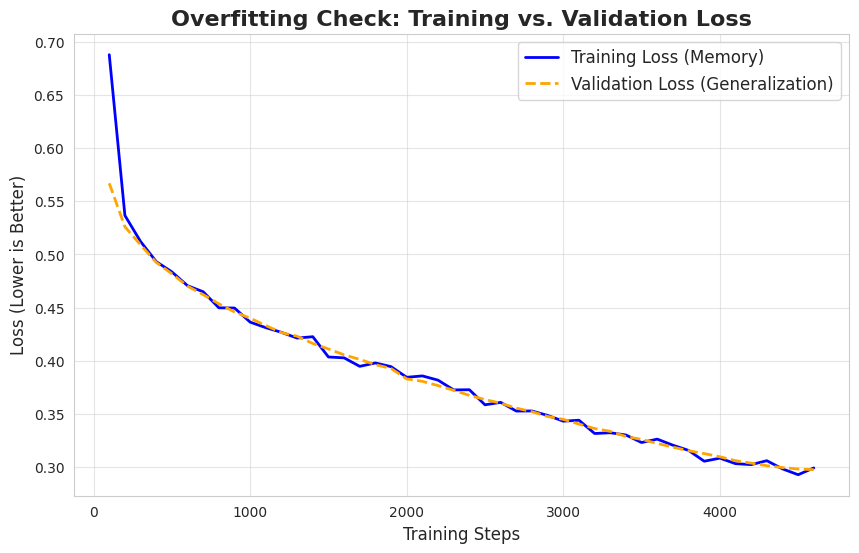

In [7]:
# ==============================================================================
# STEP 4.5: OVERFITTING CHECK (Visualization)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("\n📊 Generating Overfitting Check Graph...")

# 1. Extract Logs
history = trainer.state.log_history
train_loss = []
val_loss = []
steps_train = []
steps_val = []

for entry in history:
    if 'loss' in entry and 'step' in entry:
        train_loss.append(entry['loss'])
        steps_train.append(entry['step'])
    if 'eval_loss' in entry and 'step' in entry:
        val_loss.append(entry['eval_loss'])
        steps_val.append(entry['step'])

# 2. Plot the Graph
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Plot Training Loss (Blue)
plt.plot(steps_train, train_loss, label='Training Loss (Memory)', color='blue', linewidth=2)

# Plot Validation Loss (Orange)
if len(val_loss) > 0:
    plt.plot(steps_val, val_loss, label='Validation Loss (Generalization)', color='orange', linewidth=2, linestyle='--')
else:
    print("⚠️ Warning: No validation logs found. Did you run the Updated Training Code above?")

plt.title('Overfitting Check: Training vs. Validation Loss', fontsize=16, fontweight='bold')
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Loss (Lower is Better)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.5)

# 3. Interpretation Text
print("\n--- HOW TO READ THIS GRAPH ---")
print("✅ GOOD: Orange line goes DOWN or stays FLAT.")
print("❌ BAD (Overfitting): Orange line starts going UP while Blue line goes DOWN.")
print("------------------------------")

plt.show()

In [8]:
# ==============================================================================
# STEP 5: MULTI-METRIC EVALUATION BY DIRECTION
# ==============================================================================

print("\n📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...")

# Load Metrics
bleu = evaluate.load("sacrebleu")
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# Helper to normalize text for scoring
def normalize(text):
    return text.lower().strip().replace(".", "").replace("।", "")

# Helper to categorize directions
def get_direction(instruction):
    # Regex to find languages
    src = re.search(r"Translate this (.*?) sentence", instruction).group(1)
    tgt = re.search(r"into (.*?)\.", instruction).group(1)
    return f"{src} -> {tgt}"

# Store results
results_log = []

# Inference Mode
FastLanguageModel.for_inference(model)

# Evaluate on TEST SET (Using a subset if needed, but 5% is ~5000 rows, might take 30 mins)
# We will do 1000 samples to keep it fast for now. Change to len(test_dataset) for full.
eval_samples = 1000
subset = test_dataset.select(range(min(eval_samples, len(test_dataset))))

for item in tqdm(subset, desc="Evaluating"):
    full_text = item["text"]
    prompt = full_text.split("### Response:\n")[0] + "### Response:\n"
    reference = full_text.split("### Response:\n")[1].replace(tokenizer.eos_token, "").strip()

    # Extract Instruction for Direction
    instruction = item["instruction"]
    direction = get_direction(instruction)

    # Generate Prediction
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    # max_new_tokens=128 because sentences are longer than words
    outputs = model.generate(**inputs, max_new_tokens=128, use_cache=True)
    prediction = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    prediction = prediction.split("### Response:\n")[-1].strip()

    # Store Data
    results_log.append({
        "direction": direction,
        "reference": reference,
        "prediction": prediction
    })


📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...


Evaluating:   0%|          | 0/1000 [00:00<?, ?it/s]

In [9]:
# ==============================================================================
# STEP 6: CALCULATE & PLOT SCORES
# ==============================================================================

# Convert to DataFrame
df_res = pd.DataFrame(results_log)

# Calculate Metrics Per Direction
summary = []

unique_directions = df_res['direction'].unique()

print("\n" + "="*60)
print(f"{'DIRECTION':<40} | {'BLEU':<6} | {'WER':<6} | {'CER':<6} | {'ACC':<6}")
print("="*60)

for direction in unique_directions:
    subset = df_res[df_res['direction'] == direction]
    if len(subset) == 0: continue

    refs = subset['reference'].tolist()
    preds = subset['prediction'].tolist()

    # 1. BLEU
    # SacreBLEU expects list of lists for references
    bleu_score = bleu.compute(predictions=preds, references=refs)['score']

    # 2. WER (Word Error Rate - Lower is better)
    wer_score = wer_metric.compute(predictions=preds, references=refs)

    # 3. CER (Character Error Rate - Lower is better)
    cer_score = cer_metric.compute(predictions=preds, references=refs)

    # 4. Word Accuracy (Approximate inverse of WER, simpler exact match count)
    # Strict exact match
    exact_matches = sum([1 for p, r in zip(preds, refs) if normalize(p) == normalize(r)])
    accuracy = (exact_matches / len(preds)) * 100

    summary.append({
        "Direction": direction,
        "BLEU": bleu_score,
        "WER": wer_score,
        "CER": cer_score,
        "Accuracy": accuracy
    })

    print(f"{direction:<40} | {bleu_score:>6.2f} | {wer_score:>6.2f} | {cer_score:>6.2f} | {accuracy:>6.1f}%")

print("="*60)


DIRECTION                                | BLEU   | WER    | CER    | ACC   
Bangla -> Marma (English Script)         |   7.30 |   0.82 |   0.50 |    3.4%
Marma (English Script) -> Bangla         |  26.77 |   0.54 |   0.45 |   22.8%
Marma (English Script) -> English        |  38.46 |   0.53 |   0.38 |   26.2%
English -> Bangla                        |  62.33 |   0.21 |   0.14 |   58.3%
Bangla -> Marma (Bangla Script)          |  15.13 |   0.74 |   0.48 |    5.0%
English -> Marma (English Script)        |  13.41 |   0.78 |   0.48 |    7.6%
Bangla -> English                        |  66.59 |   0.24 |   0.17 |   54.4%
Marma (Bangla Script) -> Bangla          |  26.76 |   0.61 |   0.46 |   16.2%
Marma (Bangla Script) -> English         |  38.46 |   0.56 |   0.39 |   25.6%
English -> Marma (Bangla Script)         |  13.09 |   0.76 |   0.49 |    2.8%


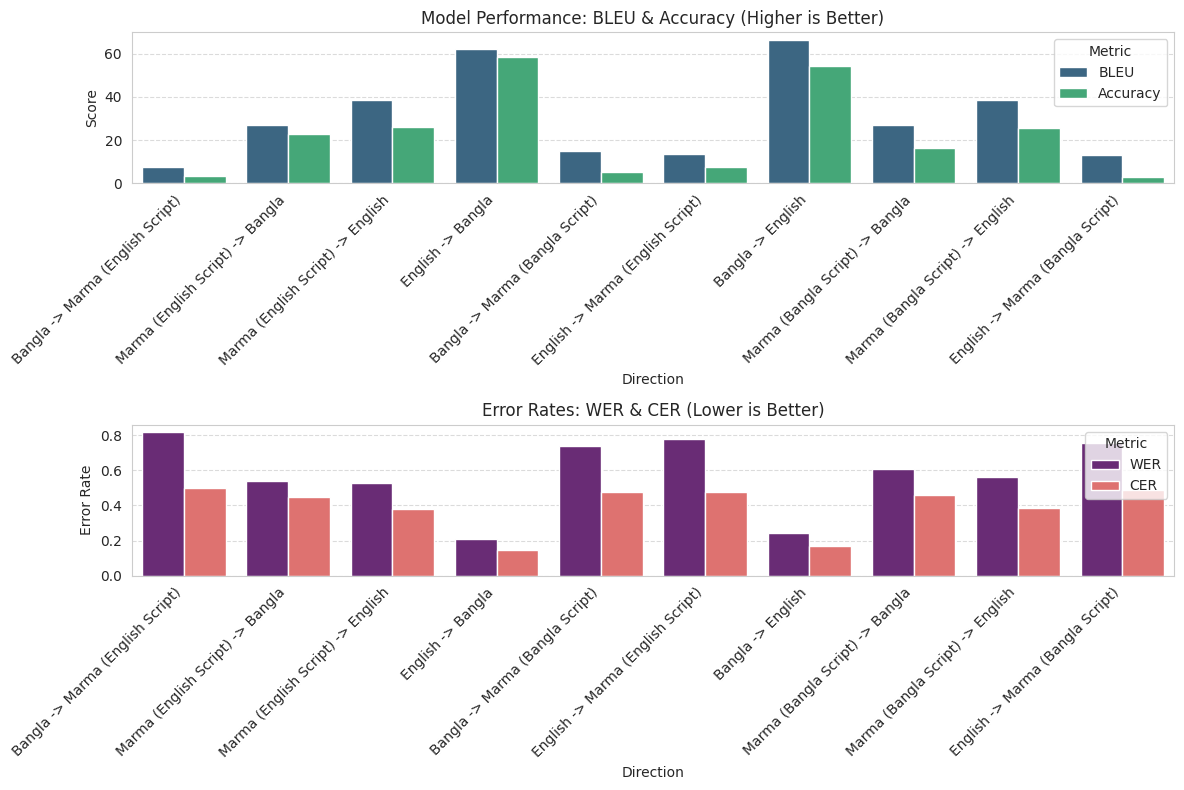


✅ PROCESS COMPLETE. Model saved and evaluation finished.


In [10]:
# ==============================================================================
# STEP 7: VISUALIZATION
# ==============================================================================

df_viz = pd.DataFrame(summary)

# Plotting
plt.figure(figsize=(12, 8))

# Subplot 1: BLEU & Accuracy (Higher is Better)
plt.subplot(2, 1, 1)
df_melt_high = df_viz.melt(id_vars="Direction", value_vars=["BLEU", "Accuracy"], var_name="Metric", value_name="Score")
sns.barplot(data=df_melt_high, x="Direction", y="Score", hue="Metric", palette="viridis")
plt.title("Model Performance: BLEU & Accuracy (Higher is Better)")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Subplot 2: WER & CER (Lower is Better)
plt.subplot(2, 1, 2)
df_melt_low = df_viz.melt(id_vars="Direction", value_vars=["WER", "CER"], var_name="Metric", value_name="Error Rate")
sns.barplot(data=df_melt_low, x="Direction", y="Error Rate", hue="Metric", palette="magma")
plt.title("Error Rates: WER & CER (Lower is Better)")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("\n✅ PROCESS COMPLETE. Model saved and evaluation finished.")